### Notebook 04: Multi-Stage Flight Simulation

This notebook simulates the complete multi-stage maneuver required for the AE 352 quadcopter project.

The drone begins on the ground, takes off to an altitude of 1 m, flies 5 m forward, stops and hovers, rotates 90 degrees to the left, flies another 5 m, stops, and lands vertically.

The simulation uses the same 16-state dynamical model from `drone_model.py`. A PD controller calculates the four motor torques needed to follow the prescribed trajectory.

The simulation runs for 272 seconds, including a gradual 250-second descent to satisfy the maximum landing speed of 0.01 m/s.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid

import drone_model as drone

# Drone hover conditions
hover_speed, hover_torque = drone.hover_conditions()

# Initial conditions
initial_state = np.zeros(16)
initial_state[12:16] = hover_speed

# Simulation time
simulation_time = 272
time_points = np.linspace(0, simulation_time, 2721)

# Motor limits
MAX_RPM = 6530
MAX_SPEED = MAX_RPM * 2 * np.pi / 60
MAX_TORQUE = 0.14

print("Simulation time:", simulation_time, "s")
print("Initial position:", initial_state[0:3])
print("Initial rotor speed:", round(hover_speed, 2), "rad/s")

Simulation time: 272 s
Initial position: [0. 0. 0.]
Initial rotor speed: 445.93 rad/s


#### Multi-Stage Trajectory

The Design Engineer defined a smooth ninth-order transition function:

$$
S(s)=126s^5-420s^6+540s^7-315s^8+70s^9
$$

where $s$ is the elapsed fraction of a maneuver segment, ranging from 0 to 1.

The first four derivatives of this function are zero at both endpoints, allowing the drone to transition smoothly between flight phases.

The desired position is calculated using:

$$
x_d(t)=5S_x(t)
$$

$$
y_d(t)=5S_y(t)
$$

$$
z_d(t)=S_{\mathrm{takeoff}}(t)-S_{\mathrm{landing}}(t)
$$

The yaw angle changes by 90 degrees during the turning phase:

$$
\psi_d(t)=\frac{\pi}{2}S_{\mathrm{yaw}}(t)
$$

The first and second derivatives of these trajectories give the desired velocity and acceleration.

A PD controller compares the desired motion with the simulated motion and determines the necessary motor torques through the quadcopter's thrust and moment equations.

In [2]:
def transition(time, start, duration):
    s = (time - start) / duration
    s = np.clip(s, 0, 1)

    position = (
        126*s**5 - 420*s**6 + 540*s**7
        - 315*s**8 + 70*s**9
    )

    velocity = (
        630*s**4 - 2520*s**5 + 3780*s**6
        - 2520*s**7 + 630*s**8
    ) / duration

    acceleration = (
        2520*s**3 - 12600*s**4 + 22680*s**5
        - 17640*s**6 + 5040*s**7
    ) / duration**2

    return position, velocity, acceleration


def mission_trajectory(time):
    # Takeoff: 0 to 4 seconds
    climb, climb_v, climb_a = transition(time, 0, 4)

    # First straight flight: 4 to 9 seconds
    leg1, leg1_v, leg1_a = transition(time, 4, 5)

    # Left yaw: 10 to 15 seconds
    turn, turn_v, turn_a = transition(time, 10, 5)

    # Second straight flight: 16 to 21 seconds
    leg2, leg2_v, leg2_a = transition(time, 16, 5)

    # Landing: 22 to 272 seconds
    land, land_v, land_a = transition(time, 22, 250)

    position = np.array([
        5 * leg1,
        5 * leg2,
        climb - land
    ])

    velocity = np.array([
        5 * leg1_v,
        5 * leg2_v,
        climb_v - land_v
    ])

    acceleration = np.array([
        5 * leg1_a,
        5 * leg2_a,
        climb_a - land_a
    ])

    yaw = (np.pi / 2) * turn
    yaw_rate = (np.pi / 2) * turn_v

    return position, velocity, acceleration, yaw, yaw_rate

In [3]:
# Controller gains
KP_XY = 2.0
KD_XY = 2.8

KP_Z = 3.0
KD_Z = 3.0

KP_ANGLE = 250.0
KD_ANGLE = 30.0

KP_YAW = 60.0
KD_YAW = 18.0

MOTOR_GAIN = 25.0

# Model parameters
k = drone.THRUST_COEFF
b = drone.DRAG_COEFF
L = drone.ARM_LENGTH

# Thrust and moment equations
mixing_matrix = np.array([
    [k, k, k, k],
    [0, L*k, 0, -L*k],
    [-L*k, 0, L*k, 0],
    [-b, b, -b, b]
])


def mission_controller(time, state):
    position, velocity, acceleration, yaw_target, yaw_rate = mission_trajectory(time)

    current_position = state[0:3]
    current_velocity = state[3:6]

    roll, pitch, yaw = state[6:9]
    p, q, r = state[9:12]
    rotor_speeds = state[12:16]

    # Position control
    position_error = position - current_position
    velocity_error = velocity - current_velocity

    kp = np.array([KP_XY, KP_XY, KP_Z])
    kd = np.array([KD_XY, KD_XY, KD_Z])

    desired_acceleration = (
        acceleration
        + kp * position_error
        + kd * velocity_error
    )

    # Required thrust
    force = drone.MASS * (
        desired_acceleration + np.array([0, 0, drone.GRAVITY])
    )

    force[2] = max(force[2], 0.1 * drone.MASS * drone.GRAVITY)

    total_thrust = np.linalg.norm(force)

    # Desired roll and pitch
    forward_force = (
        np.cos(yaw_target) * force[0]
        + np.sin(yaw_target) * force[1]
    )

    left_force = (
        -np.sin(yaw_target) * force[0]
        + np.cos(yaw_target) * force[1]
    )

    desired_roll = -np.arcsin(
        np.clip(left_force / total_thrust, -0.999, 0.999)
    )

    desired_pitch = np.arctan2(
        forward_force, force[2]
    )

    desired_roll = np.clip(desired_roll, -0.35, 0.35)
    desired_pitch = np.clip(desired_pitch, -0.35, 0.35)

    # Desired body rates during yaw
    p_target = -np.sin(desired_pitch) * yaw_rate

    q_target = (
        np.sin(desired_roll)
        * np.cos(desired_pitch)
        * yaw_rate
    )

    r_target = (
        np.cos(desired_roll)
        * np.cos(desired_pitch)
        * yaw_rate
    )

    # Yaw angle error
    yaw_error = np.arctan2(
        np.sin(yaw_target - yaw),
        np.cos(yaw_target - yaw)
    )

    # Attitude control
    torque_x = drone.IX * (
        KP_ANGLE * (desired_roll - roll)
        + KD_ANGLE * (p_target - p)
    ) + (drone.IZ - drone.IY) * q * r

    torque_y = drone.IY * (
        KP_ANGLE * (desired_pitch - pitch)
        + KD_ANGLE * (q_target - q)
    ) + (drone.IX - drone.IZ) * p * r

    torque_z = drone.IZ * (
        KP_YAW * yaw_error
        + KD_YAW * (r_target - r)
    ) + (drone.IY - drone.IX) * p * q

    # Required thrust and moments
    commands = np.array([
        total_thrust,
        torque_x,
        torque_y,
        torque_z
    ])

    # Convert commands into rotor speeds
    speed_squared = np.linalg.solve(mixing_matrix, commands)
    speed_squared = np.clip(speed_squared, 0, MAX_SPEED**2)

    desired_speeds = np.sqrt(speed_squared)

    # Convert rotor speed commands into motor torques
    motor_torques = (
        b * rotor_speeds**2
        + drone.ROTOR_INERTIA * MOTOR_GAIN
        * (desired_speeds - rotor_speeds)
    )

    motor_torques = np.clip(motor_torques, 0, MAX_TORQUE)

    return motor_torques

In [4]:
def controlled_dynamics(time, state):
    motor_torques = mission_controller(time, state)
    return drone.drone_derivatives(time, state, motor_torques)


solution = solve_ivp(
    controlled_dynamics,
    (0, simulation_time),
    initial_state,
    t_eval=time_points,
    rtol=1e-7,
    atol=1e-9,
    max_step=0.1
)

assert solution.success, solution.message

print("Solver successful:", solution.success)
print("Simulation duration:", solution.t[-1], "s")
print("Final position:", solution.y[0:3, -1])
print("Final attitude:", np.degrees(solution.y[6:9, -1]))

Solver successful: True
Simulation duration: 272.0 s
Final position: [5.00000000e+00 5.00000000e+00 1.31986415e-10]
Final attitude: [-1.68101981e-15 -6.02089117e-16  9.00000000e+01]


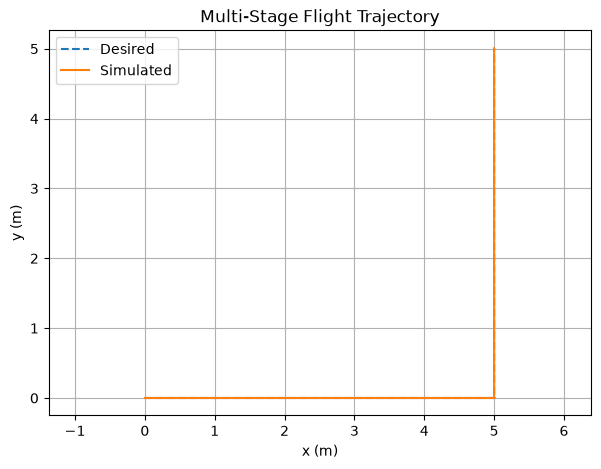

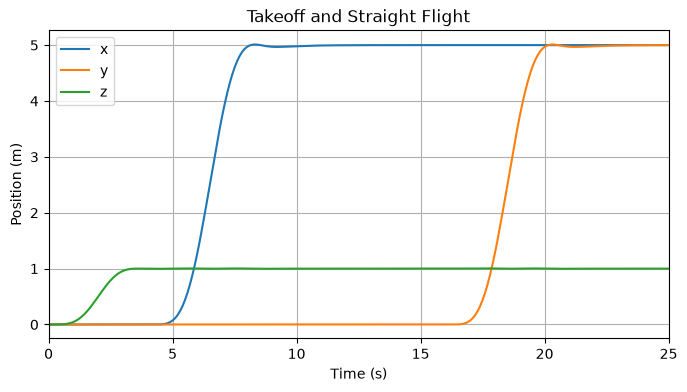

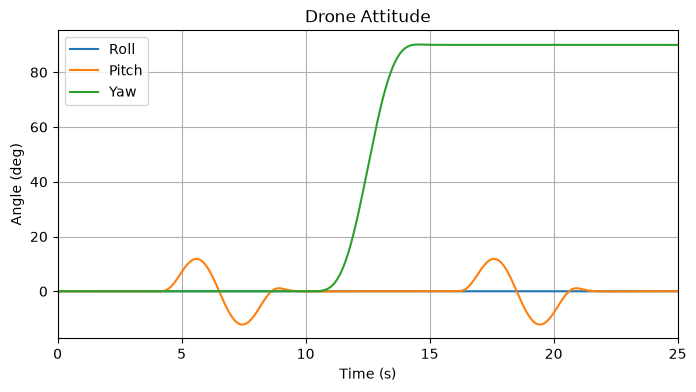

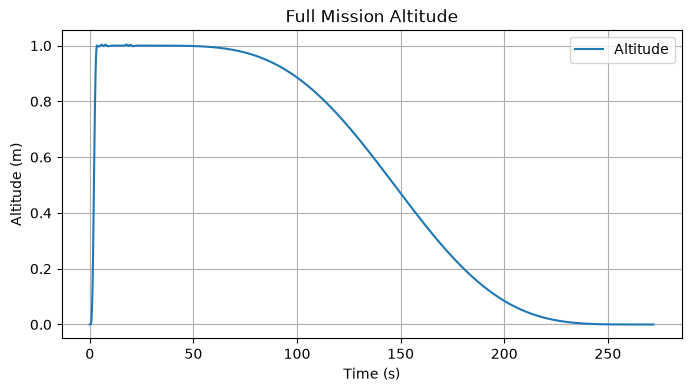

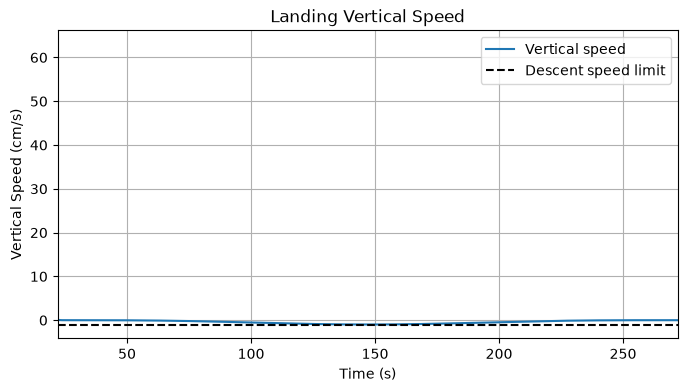

In [5]:
time = solution.t

x = solution.y[0]
y = solution.y[1]
z = solution.y[2]

vx = solution.y[3]
vy = solution.y[4]
vz = solution.y[5]

roll = np.degrees(solution.y[6])
pitch = np.degrees(solution.y[7])
yaw = np.degrees(solution.y[8])

# Reference trajectory
reference_position = np.array([
    mission_trajectory(t)[0] for t in time
])

# Horizontal trajectory
plt.figure(figsize=(7, 5))
plt.plot(reference_position[:, 0], reference_position[:, 1],
         "--", label="Desired")
plt.plot(x, y, label="Simulated")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Multi-Stage Flight Trajectory")
plt.axis("equal")
plt.legend()
plt.grid()
plt.show()

# Position during takeoff and straight flights
plt.figure(figsize=(8, 4))
plt.plot(time, x, label="x")
plt.plot(time, y, label="y")
plt.plot(time, z, label="z")
plt.xlim(0, 25)
plt.xlabel("Time (s)")
plt.ylabel("Position (m)")
plt.title("Takeoff and Straight Flight")
plt.legend()
plt.grid()
plt.show()

# Attitude during maneuvers
plt.figure(figsize=(8, 4))
plt.plot(time, roll, label="Roll")
plt.plot(time, pitch, label="Pitch")
plt.plot(time, yaw, label="Yaw")
plt.xlim(0, 25)
plt.xlabel("Time (s)")
plt.ylabel("Angle (deg)")
plt.title("Drone Attitude")
plt.legend()
plt.grid()
plt.show()

# Landing altitude and vertical speed
plt.figure(figsize=(8, 4))
plt.plot(time, z, label="Altitude")
plt.xlabel("Time (s)")
plt.ylabel("Altitude (m)")
plt.title("Full Mission Altitude")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(time, vz * 100, label="Vertical speed")
plt.axhline(-1.0, color="black", linestyle="--",
            label="Descent speed limit")
plt.xlim(22, 272)
plt.xlabel("Time (s)")
plt.ylabel("Vertical Speed (cm/s)")
plt.title("Landing Vertical Speed")
plt.legend()
plt.grid()
plt.show()

In [7]:
# Find the simulation indices for each maneuver
i4 = np.argmin(np.abs(time - 4))
i9 = np.argmin(np.abs(time - 9))
i10 = np.argmin(np.abs(time - 10))
i15 = np.argmin(np.abs(time - 15))
i16 = np.argmin(np.abs(time - 16))
i21 = np.argmin(np.abs(time - 21))
i22 = np.argmin(np.abs(time - 22))

# Straight flight distances
distance1 = x[i9] - x[i4]
distance2 = y[i21] - y[i16]

average_speed1 = distance1 / 5
average_speed2 = distance2 / 5

# Yaw rotation
yaw_change = yaw[i15] - yaw[i10]

# Hover speeds after each stop
speed = np.sqrt(vx**2 + vy**2 + vz**2)

hover_speed1 = speed[i10]
hover_speed2 = speed[i16]
hover_speed3 = speed[i22]

# Landing verification
landing = time >= 22

max_descent_speed = np.max(np.abs(vz[landing]))
touchdown_speed = abs(vz[-1])

print("First leg distance:", round(distance1, 3), "m")
print("Second leg distance:", round(distance2, 3), "m")
print("First leg average speed:", round(average_speed1, 3), "m/s")
print("Second leg average speed:", round(average_speed2, 3), "m/s")
print("Yaw rotation:", round(yaw_change, 3), "deg")

print("Hover stop speeds:",
      round(hover_speed1, 4),
      round(hover_speed2, 4),
      round(hover_speed3, 4), "m/s")

print("Maximum landing descent speed:",
      round(max_descent_speed, 6), "m/s")

print("Touchdown speed:", round(touchdown_speed, 6), "m/s")
print("Final altitude:", round(z[-1], 6), "m")

# Check flight requirements
distance_pass = (
    abs(distance1 - 5) < 0.05
    and abs(distance2 - 5) < 0.05
)

speed_pass = abs(average_speed1 - 1.0) < 0.05

yaw_pass = abs(yaw_change - 90) < 1.0

hover_pass = (
    hover_speed1 < 0.05
    and hover_speed2 < 0.05
    and hover_speed3 < 0.05
)

landing_pass = (
    max_descent_speed <= 0.01 + 1e-6
    and abs(z[-1]) < 0.01
)

print("Distance requirement passed:", distance_pass)
print("Speed requirement passed:", speed_pass)
print("Yaw requirement passed:", yaw_pass)
print("Hover stops passed:", hover_pass)
print("Landing requirement passed:", landing_pass)

# Electrical energy
power = []

for i in range(len(time)):
    speeds = solution.y[12:16, i]
    power.append(drone.electrical_power(speeds))

power = np.array(power)
total_energy = trapezoid(power, time) / 3600

usable_energy = (
    drone.BATTERY_VOLTAGE
    * drone.BATTERY_CAPACITY
    * (1 - drone.BATTERY_RESERVE)
)

print("Mission energy:", round(total_energy, 3), "Wh")
print("Usable battery energy:", round(usable_energy, 2), "Wh")
print("Energy requirement passed:", total_energy < usable_energy)

# Motor limits
motor_inputs = []

for i in range(len(time)):
    motor_inputs.append(
        mission_controller(time[i], solution.y[:, i])
    )

motor_inputs = np.array(motor_inputs)

max_rpm = np.max(solution.y[12:16]) * 60 / (2*np.pi)
max_torque = np.max(motor_inputs)

print("Maximum rotor speed:", round(max_rpm, 1), "RPM")
print("Maximum motor torque:", round(max_torque, 4), "Nm")

print("Rotor speed limit passed:", max_rpm <= MAX_RPM)
print("Motor torque limit passed:", max_torque <= MAX_TORQUE)

mission_pass = (
    distance_pass
    and speed_pass
    and yaw_pass
    and hover_pass
    and landing_pass
    and total_energy < usable_energy
    and max_rpm <= MAX_RPM
    and max_torque <= MAX_TORQUE
)

print("Multi-stage maneuver passed:", mission_pass)

First leg distance: 4.97 m
Second leg distance: 4.97 m
First leg average speed: 0.994 m/s
Second leg average speed: 0.994 m/s
Yaw rotation: 90.039 deg
Hover stop speeds: 0.0189 0.0 0.0189 m/s
Maximum landing descent speed: 0.009844 m/s
Touchdown speed: 0.0 m/s
Final altitude: 0.0 m
Distance requirement passed: True
Speed requirement passed: True
Yaw requirement passed: True
Hover stops passed: True
Landing requirement passed: True
Mission energy: 10.842 Wh
Usable battery energy: 44.4 Wh
Energy requirement passed: True
Maximum rotor speed: 4387.9 RPM
Maximum motor torque: 0.0594 Nm
Rotor speed limit passed: True
Motor torque limit passed: True
Multi-stage maneuver passed: True
